# 04 Content based recommender

**Workshop:** LU2 `06_Recommender systems` (Bag of Words, cosine similarity, zoeken op titel).

Een content based recommender vergelijkt **kenmerken van het materiaal** met het **profiel van de student**. Er zijn geen
beoordelingen van anderen nodig, dus het werkt ook voor een nieuwe student (*cold start*).

In [1]:
import sys
from pathlib import Path

# Make the project package importable, also without "pip install -e ."
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from reading_coach import config

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
from reading_coach.content import ContentModel
from reading_coach.data_cleaning import load_processed

materials, students, interactions = load_processed()
content = ContentModel().fit(materials)
titles = materials.set_index("catalog_code")["title"]

## 1. Cosine similarity tussen materialen

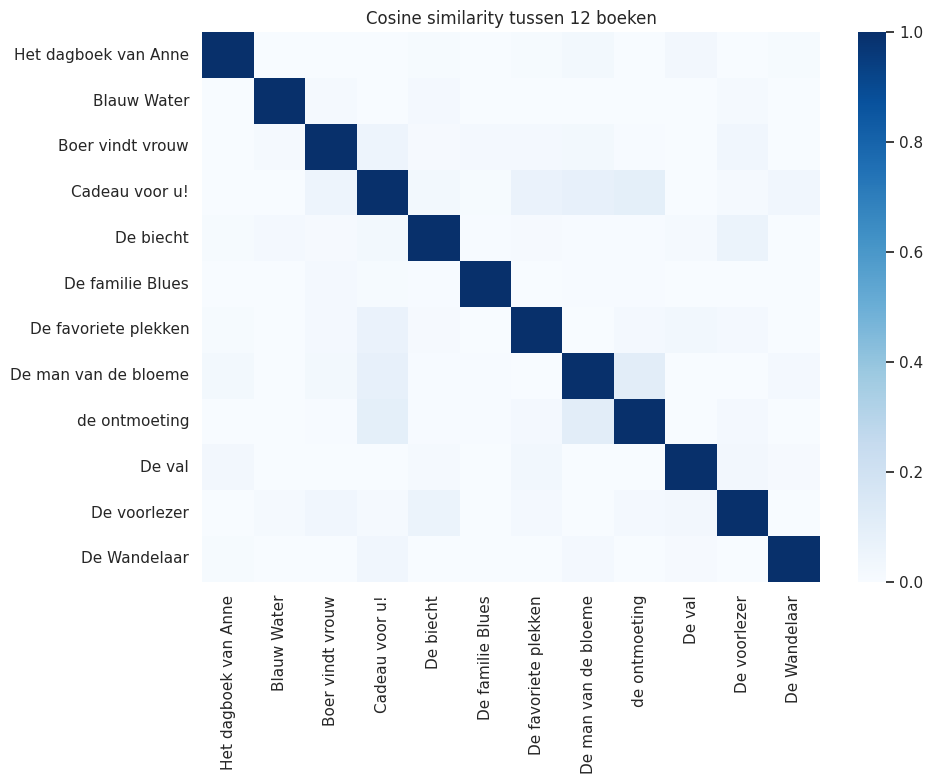

In [3]:
similarity = content.item_similarity()
sample = materials["type"].eq("boek").to_numpy().nonzero()[0][:12]
plt.figure(figsize=(10, 8))
sns.heatmap(similarity[np.ix_(sample, sample)], xticklabels=materials["title"].iloc[sample].str[:20],
            yticklabels=materials["title"].iloc[sample].str[:20], cmap="Blues")
plt.title("Cosine similarity tussen 12 boeken")
plt.tight_layout()
plt.show()

## 2. Lijkt op: materialen die op een gekozen titel lijken

In [4]:
def similar_to(title: str, top_n: int = 5) -> pd.DataFrame:
    code = materials.loc[materials["title"].str.contains(title, case=False), "catalog_code"].iat[0]
    rows = [(titles[other], round(score, 3)) for other, score in content.similar_items(code, top_n)]
    print("Lijkt op:", titles[code])
    return pd.DataFrame(rows, columns=["title", "cosine_similarity"])

similar_to("Anne Frank")

Lijkt op: Het dagboek van Anne Frank


,title,cosine_similarity
0,Het meisje dat er niet mocht zijn,0.134
1,Doe het toch maar,0.110
2,Haar leven,0.098
3,Neem de tijd,0.097
4,De jongen in de gestreepte pyjama,0.072


## 3. Zoeken met een vrije tekst

In [5]:
pd.DataFrame([(titles[code], round(score, 3)) for code, score in content.search("spannend boek over criminaliteit en geheimen")],
             columns=["title", "score"])

,title,score
0,Pizzamaffia slaat door,0.220
1,De vijf die blijven,0.133
2,Wie zit in de gevangenis? En andere bijzondere...,0.132
3,Zonder spijt,0.127
4,Kater,0.127


## 4. Profiel van een student als zoekvraag
Het profiel bestaat uit de interesses (uitgebreid met verwante thema's uit de catalogus) en, als die er zijn, het gemiddelde van de materialen die de student goed vond.

In [6]:
student = students.iloc[0]
liked = interactions.query("student_id == @student.student_id and preference_score >= 4")["catalog_code"].tolist()
interests = student["interests"].split(";")
print("Student", student["student_id"], "interesses:", interests, "| eerder goed gevonden:", len(liked))

scores = pd.Series(content.scores(interests, liked), index=content.codes)
top = scores.drop(index=liked, errors="ignore").nlargest(5)
pd.DataFrame({
    "title": titles[top.index].to_numpy(),
    "score": top.round(3).to_numpy(),
    "interesse in tekst": [", ".join(content.interest_matches(interests, code)) for code in top.index],
})

Student S001 interesses: ['kunstmatige intelligentie', 'relaties'] | eerder goed gevonden: 7


,title,score,interesse in tekst
0,Moeder mijn vrouw,0.303,relaties
1,De voorlezer,0.209,relaties
2,De nacht van Faris,0.156,
3,Komt een vrouw bij de dokter,0.153,relaties
4,Hotel rozenstok,0.115,relaties


## 5. Beperkingen van alleen content based

In [7]:
from reading_coach.features import StudentProfile, static_features
from reading_coach.vocabulary import Vocabulary

vocabulary = Vocabulary.learn(materials, interactions)
profile = StudentProfile.from_dataset_row(student, vocabulary)
check = static_features(profile, materials, vocabulary).loc[top.index, ["level_diff", "type_match", "genre_match", "fits_time"]]
check.insert(0, "title", titles[top.index].to_numpy())
check

,title,level_diff,type_match,genre_match,fits_time
CAT-00028,Moeder mijn vrouw,1.0,1.0,0.0,0.0
CAT-00011,De voorlezer,1.0,1.0,0.0,0.0
CAT-00205,De nacht van Faris,1.0,1.0,0.0,0.0
CAT-00025,Komt een vrouw bij de dokter,1.0,1.0,0.0,0.0
CAT-00045,Hotel rozenstok,1.0,1.0,0.0,0.0


Puur op tekst kijken negeert het **niveau**, het **type**, de **leestijd** en wat **andere studenten** ervan vonden.
Een tekstueel perfect boek kan dus te moeilijk of te lang zijn. In notebook 06 combineren we daarom content based scores
met deze kenmerken en met collaborative filtering in een getraind model.